In [86]:
import pandas as pd
import seaborn as sns
import numpy as np

In [87]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
bike_sharing = fetch_ucirepo(id=275) 
  
# data (as pandas dataframes) 
X = bike_sharing.data.features 
y = bike_sharing.data.targets 
  

In [88]:
# metadata 
print(bike_sharing.metadata) 

{'uci_id': 275, 'name': 'Bike Sharing', 'repository_url': 'https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset', 'data_url': 'https://archive.ics.uci.edu/static/public/275/data.csv', 'abstract': 'This dataset contains the hourly and daily count of rental bikes between years 2011 and 2012 in Capital bikeshare system with the corresponding weather and seasonal information.', 'area': 'Social Science', 'tasks': ['Regression'], 'characteristics': ['Multivariate'], 'num_instances': 17389, 'num_features': 13, 'feature_types': ['Integer', 'Real'], 'demographics': [], 'target_col': ['cnt'], 'index_col': ['instant'], 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2013, 'last_updated': 'Sun Mar 10 2024', 'dataset_doi': '10.24432/C5W894', 'creators': ['Hadi Fanaee-T'], 'intro_paper': {'ID': 422, 'type': 'NATIVE', 'title': 'Event labeling combining ensemble detectors and background knowledge', 'authors': 'Hadi Fanaee-T, João Gama', 'venue': 'Progress

In [89]:
# variable information 
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   dteday      17379 non-null  str    
 1   season      17379 non-null  int64  
 2   yr          17379 non-null  int64  
 3   mnth        17379 non-null  int64  
 4   hr          17379 non-null  int64  
 5   holiday     17379 non-null  int64  
 6   weekday     17379 non-null  int64  
 7   workingday  17379 non-null  int64  
 8   weathersit  17379 non-null  int64  
 9   temp        17379 non-null  float64
 10  atemp       17379 non-null  float64
 11  hum         17379 non-null  float64
 12  windspeed   17379 non-null  float64
dtypes: float64(4), int64(8), str(1)
memory usage: 1.7 MB


In [90]:
print(X.shape)
print(X.size)

(17379, 13)
225927


In [91]:
y.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   cnt     17379 non-null  int64
dtypes: int64(1)
memory usage: 135.9 KB


In [92]:
X.duplicated().any()

# if true is returned then use:
# X.duplicated().sum()

np.False_

In [93]:
X.isnull().sum()

dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
dtype: int64

In [94]:
display(X.describe().T)
# display(y.describe().T)

,count,mean,std,min,25%,50%,75%,max
season,17379.0,2.501640,1.106918,1.00,2.0000,3.0000,3.0000,4.0000
yr,17379.0,0.502561,0.500008,0.00,0.0000,1.0000,1.0000,1.0000
mnth,17379.0,6.537775,3.438776,1.00,4.0000,7.0000,10.0000,12.0000
hr,17379.0,11.546752,6.914405,0.00,6.0000,12.0000,18.0000,23.0000
holiday,17379.0,0.028770,0.167165,0.00,0.0000,0.0000,0.0000,1.0000
weekday,17379.0,3.003683,2.005771,0.00,1.0000,3.0000,5.0000,6.0000
workingday,17379.0,0.682721,0.465431,0.00,0.0000,1.0000,1.0000,1.0000
weathersit,17379.0,1.425283,0.639357,1.00,1.0000,1.0000,2.0000,4.0000
temp,17379.0,0.496987,0.192556,0.02,0.3400,0.5000,0.6600,1.0000
atemp,17379.0,0.475775,0.171850,0.00,0.3333,0.4848,0.6212,1.0000


- **season**: 2.5 mean means that most of the records are between 2-3 period, so people use bikes more between spring and summer,
              also a low std of 1.1 and again 50-75% percent fall under 3.0 so most people rent bikes in summer

- **yr**    : 0.5 mean suggests sort of even records between 2011 and 2012, sort of even std 0.5, also 50-75% of records fall under 1
              category which means most people rented bikes in 2012 than 2011

- **mnth**  : 6.5 mean means suggests more rents around the 6th month (or summer period generally), also 3.4 std suggests big
              distribution, also 50% of rents are on the 7th month so july and 75% of rented bikes are on the 10th month so october, so most rented bikes fall on the 10th and under (before) the 10th month (october)?

- **hr**    : 11.5 mean shows that around noon time there are more rents, huge variation with std 6.9, and most of the rents happen
              before 6pm (75% 18.0) and 50% are at 12 in the morninng and before, so more people rent in the morning (to go to work if theyre working) than coming back from home

- **holiday**: 0.68 mean which is quite even between the 0 and 1 values it has, and low of std 0.4, and also shows that under the
               25-50-75 percent categories 0.0 is the main value, which suggests people rent bikes more when theyre NOT on holiday

- **weekday**: 3.0 weekday suggests more people rented bikes on thursday (if 0 is monday and not sunday) or wednesday (if 0 is
               sunday), 50% of the rented bikes fall under the 3rd day which again suggests half of the people rent bikes before the 3rd day of the week and 75% before the 5th and before (so possibly up until friday?). so another reason would be that people get tired by the end of their working week and are less likely to rent on thrusdays and fridays than monday tuesday and wednesday.

- **workingday**: 1 if day is not weekend or holiday, otherwise 0. the 0.68 mean shows that it is quite balanced and a bit more skewed
                  towards 1 (?), so more people tend to rent bikes when its a working day, and then 50-75% fall under the 1st category so i think its fair to say most people dont use bikes when on holiday or is the weekend.

- **weathersit**: 1.4 mean suggests that people rent mostly when the weather is clear or there are a few clouds (1 is clear,
                  2 few clouds, 3 partly cloudy, 4 more cloudy), also 50% of records fall under the 1st one and 75% fall under the 2nd one, with a low std of 0.6. so most people do rent when the weather is good.

- **temp**  : cant really understand the values compared to what float values the records have which according to the website t_min
              is 8 and t_max is 39 in hourly scale (whatever that means). what i do understand is with the max value being one, 75% of records fall under this 0.66 which is quite close to 1, and if 1 is the warmest the temp can be, then most of the records (bike rentals) are happening when temp is high.

- **atemp** : same as above but t_min is 16 and t_max 50 in hourly scale (?). same as above, the max is 1 and 75% of the records fall
          under 0.6 so rented bikes are favoured when it comes to higher temperatures i think.

- **hum**  : 0.62 mean, 0.19 std, 75% under 0.78- with max 1.0- suggests that people prefer renting bikes when its more humid outside
          than when it isnt. but then, how much is humidity tied to temperature (and seasons/months), which i can see on the next step.

- **windspeed** : a very low 0.19 mean and an extremely low 0.12 std suggests that most people prefer bikes when the arent strong
                  winds. also, 75% fall under 0.25 windspeed which is very low when compared to the max value of the feature being 0.85. so more bikes are rented when the wind is more

#### ALL OF THE ABOVE ARE INACCURATE (at least w/ just the above values) SINCE THEY'RE BASED ON WRONG ASSUMPTIONS OF HAVING RENTED BIKES PER PER DAY/OR EVEN PER HOUR. WHEREAS THE TRUE COMPARISON SHOULD BE HOW BIKE RENTAL DEMAND CHANGES DURING A DAY SINCE PER RECORD IS PER HOUR, NOT PER DAY

In [95]:
df = X.join(y)

In [96]:
print(df.describe().T)

              count        mean         std   min      25%       50%  \
season      17379.0    2.501640    1.106918  1.00   2.0000    3.0000   
yr          17379.0    0.502561    0.500008  0.00   0.0000    1.0000   
mnth        17379.0    6.537775    3.438776  1.00   4.0000    7.0000   
hr          17379.0   11.546752    6.914405  0.00   6.0000   12.0000   
holiday     17379.0    0.028770    0.167165  0.00   0.0000    0.0000   
weekday     17379.0    3.003683    2.005771  0.00   1.0000    3.0000   
workingday  17379.0    0.682721    0.465431  0.00   0.0000    1.0000   
weathersit  17379.0    1.425283    0.639357  1.00   1.0000    1.0000   
temp        17379.0    0.496987    0.192556  0.02   0.3400    0.5000   
atemp       17379.0    0.475775    0.171850  0.00   0.3333    0.4848   
hum         17379.0    0.627229    0.192930  0.00   0.4800    0.6300   
windspeed   17379.0    0.190098    0.122340  0.00   0.1045    0.1940   
cnt         17379.0  189.463088  181.387599  1.00  40.0000  142.

**Target variable (`cnt`)**

- The average hourly rental count is approximately 189.5 bikes across the 17,379 observations.
- The median is 142 bikes per hour, meaning half of the recorded hours had 142 or fewer rentals.
- The 75th percentile is 281, meaning approximately 75% of hourly observations had 281 or fewer rentals.
- The maximum observed hourly rental count is 977 bikes.
- The mean is higher than the median, suggesting that some hours with high rental counts pull the average upwards. The distribution can be examined further during EDA.
- The standard deviation of approximately 181.4 indicates considerable variation in hourly rental counts.

In [97]:
df.head(24)

,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,cnt
0,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0000,16
1,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0000,40
2,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0000,32
3,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0000,13
4,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0000,1
5,2011-01-01,1,0,1,5,0,6,0,2,0.24,0.2576,0.75,0.0896,1
6,2011-01-01,1,0,1,6,0,6,0,1,0.22,0.2727,0.80,0.0000,2
7,2011-01-01,1,0,1,7,0,6,0,1,0.20,0.2576,0.86,0.0000,3
8,2011-01-01,1,0,1,8,0,6,0,1,0.24,0.2879,0.75,0.0000,8
9,2011-01-01,1,0,1,9,0,6,0,1,0.32,0.3485,0.76,0.0000,14


In [98]:
random_friday_demand = df[df["dteday"] == "2012-08-24"]

random_friday_demand.head(24)


,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,cnt
14299,2012-08-24,3,1,8,0,0,5,1,2,0.66,0.6212,0.69,0.0000,111
14300,2012-08-24,3,1,8,1,0,5,1,2,0.64,0.6061,0.73,0.0000,42
14301,2012-08-24,3,1,8,2,0,5,1,1,0.66,0.6212,0.69,0.0000,16
14302,2012-08-24,3,1,8,3,0,5,1,1,0.64,0.6061,0.73,0.0000,8
14303,2012-08-24,3,1,8,4,0,5,1,2,0.64,0.6061,0.73,0.0000,8
14304,2012-08-24,3,1,8,5,0,5,1,1,0.64,0.5909,0.78,0.0000,38
14305,2012-08-24,3,1,8,6,0,5,1,2,0.62,0.5758,0.83,0.0000,151
14306,2012-08-24,3,1,8,7,0,5,1,2,0.64,0.5909,0.78,0.0000,425
14307,2012-08-24,3,1,8,8,0,5,1,2,0.66,0.6212,0.74,0.0000,744
14308,2012-08-24,3,1,8,9,0,5,1,2,0.72,0.6667,0.58,0.0000,389


In [99]:
random_monday_demand = df[df["dteday"] == "2012-05-21"]

random_monday_demand.head(24)


,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,cnt
12019,2012-05-21,2,1,5,0,0,1,1,3,0.58,0.5455,0.88,0.2985,40
12020,2012-05-21,2,1,5,1,0,1,1,3,0.58,0.5455,0.88,0.3582,15
12021,2012-05-21,2,1,5,2,0,1,1,3,0.56,0.5303,0.94,0.2537,11
12022,2012-05-21,2,1,5,3,0,1,1,2,0.56,0.5303,0.88,0.2985,2
12023,2012-05-21,2,1,5,4,0,1,1,3,0.56,0.5303,0.88,0.2985,7
12024,2012-05-21,2,1,5,5,0,1,1,3,0.56,0.5303,0.88,0.2985,15
12025,2012-05-21,2,1,5,6,0,1,1,3,0.56,0.5303,0.88,0.2985,79
12026,2012-05-21,2,1,5,7,0,1,1,3,0.56,0.5303,0.88,0.2985,153
12027,2012-05-21,2,1,5,8,0,1,1,3,0.56,0.5303,0.88,0.2537,270
12028,2012-05-21,2,1,5,9,0,1,1,3,0.56,0.5303,0.88,0.2239,186


## Initial EDA: Comparing Three Sample Days

*These are preliminary observations based on three selected days. They are useful for identifying patterns and generating hypotheses, but they are not sufficient to establish general trends or causal relationships.*

### **1. Comparing a Friday in August with a Monday in May**

- **Overall rental demand:** The selected Friday in August 2012 had substantially more rentals than the selected Monday in May 2012. Summing the hourly rental counts gives 7,582 rentals for the Friday and 4,359 for the Monday.

- **Temperature:** The normalised temperature (`temp`) and apparent temperature (`atemp`) are generally higher on the August Friday than on the May Monday. This suggests that the selected August day was warmer.

- **Humidity and wind speed:** Humidity and wind speed are generally higher during several of the Monday's early hours. Both variables decrease during the afternoon and evening, although their values vary throughout each day.

- **Weather conditions:** The Friday contains mostly weather category 2 observations, representing mist and cloudy conditions, with some category 1 observations. The Monday contains several category 3 observations in the morning, followed by improving conditions later in the day.

- **Potential explanation:** The differences in temperature, weather and wind speed may help explain the difference in rental demand. However, these observations alone cannot establish which factors contributed most to the difference. The weekday, seasonal effects and other influences should also be considered.

### **2. Hourly rental patterns on the two working days**

- **Evening demand:** Both days show higher rental counts during the late afternoon and early evening. On the August Friday, rentals peak at 17:00 (5 PM), reaching 812, while the Monday peaks at 18:00 (6 PM), reaching 530.

- **Morning demand:** Both days also show a morning increase. The August Friday reaches 744 rentals at 08:00 (8 AM), while the Monday reaches 270 at the same hour.

- **Differences in peak demand:** The Friday has five hours with more than 500 rentals, at 08:00 and from 16:00 to 19:00. The Monday has two such hours, at 17:00 and 18:00.

- **Potential explanation:** These morning and evening patterns are consistent with commuting-related demand, particularly because both dates are working days. However, more dates should be examined before concluding that this is the typical pattern.

### **3. Examining 1 January 2011**

- **Daily pattern:** The selected Saturday in January 2011 has relatively low rental counts during the early morning. Demand rises through the morning and early afternoon, peaking at 15:00 (3 PM) with 110 rentals, before declining later in the day.

- **Season and temperature:** The date belongs to winter, and its normalised temperatures are generally lower than those recorded on the two selected days in 2012.

- **Weather conditions:** The day includes a mixture of weather categories 1, 2 and 3. Weather conditions are therefore not uniformly clear throughout the day.

- **Potential explanation:** The lower rental counts may be associated with the season, weather, weekday or other differences. Because this observation is from a Saturday in 2011, while the other two are working days in 2012, it is not possible to isolate the effect of winter or weather from this comparison alone.

### **4. Questions to investigate further**

- Does average hourly rental demand vary by hour of the day?
- Are average rental counts higher in summer than in spring or winter?
- How does demand differ between working days and weekends?
- Are higher temperatures associated with higher average rental counts?
- Do adverse weather conditions correspond to lower demand?

These questions will guide the next stage of exploratory data analysis, where the full dataset can be examined using grouped statistics and visualisations.

In [100]:
hourly_stats = df.groupby("hr")["cnt"].describe()

display(hourly_stats)

,count,mean,std,min,25%,50%,75%,max
hr,,,,,,,,
0,726.0,53.898072,42.307910,2.0,25.00,40.0,69.00,283.0
1,724.0,33.375691,33.538727,1.0,11.00,20.0,42.25,168.0
2,715.0,22.869930,26.578642,1.0,5.00,11.0,28.50,132.0
3,697.0,11.727403,13.239190,1.0,3.00,6.0,15.00,79.0
4,697.0,6.352941,4.143818,1.0,3.00,6.0,8.00,28.0
5,717.0,19.889819,13.200765,1.0,8.00,19.0,29.00,66.0
6,725.0,76.044138,55.084348,1.0,23.00,76.0,117.00,213.0
7,727.0,212.064649,161.441936,1.0,55.50,208.0,332.00,596.0
8,727.0,359.011004,235.189285,5.0,131.50,385.0,559.50,839.0


8	727.0	359.011004	235.189285	5.0	    131.50	385.0	559.50	839.0
17	730.0	461.452055	232.656611	15.0	262.25	475.0	604.75	976.0
18	728.0	425.510989	224.639304	23.0	235.00	418.5	562.25	977.0

### Hourly bike-rental demand

- **Average demand:** Average hourly rentals are highest at 5 PM (approximately 461 bikes), followed by 6 PM (426) and 8 AM (359). This supports my initial observation that demand tends to peak during the morning and late-afternoon periods.

- **Standard deviation:** These hours have relatively high standard deviations: approximately 235 at 8 AM, 233 at 5 PM and 225 at 6 PM. This indicates considerable variability in rental counts across observations for these hours. The standard deviation is a separate measure of variability, rather than something that necessarily increases with the mean.

- **75th percentile:** The 75th percentiles are approximately 560 rentals at 8 AM, 605 at 5 PM and 562 at 6 PM. This means that approximately 75% of observations for each hour had rental counts at or below the corresponding value. These thresholds are relatively similar, although the 5 PM threshold is somewhat higher.

- **Maximum demand:** The maximum recorded rental counts were 839 at 8 AM, 976 at 5 PM and 977 at 6 PM. These values show that exceptionally high rental counts occurred during the late-afternoon period, although maximum values alone do not establish a typical pattern.

- **Possible explanation:** The morning and late-afternoon peaks may be associated with commuting patterns. This is a hypothesis to investigate, rather than a conclusion established by these statistics alone.

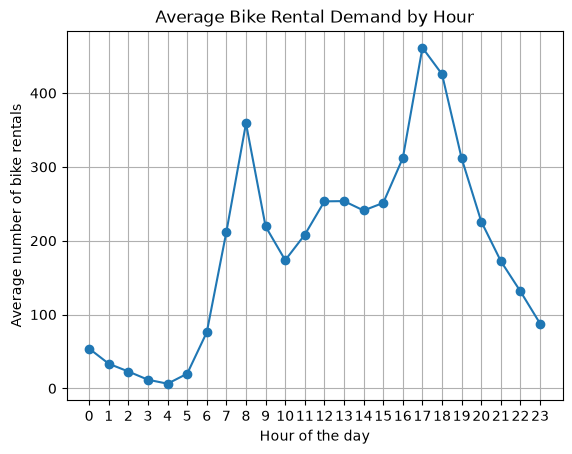

In [101]:
import matplotlib.pyplot as plt

hourly_demand = df.groupby("hr")["cnt"].mean()

hourly_demand.plot(kind="line", marker="o")

plt.xlabel("Hour of the day")
plt.ylabel("Average number of bike rentals")
plt.title("Average Bike Rental Demand by Hour")
plt.xticks(range(24))
plt.grid(True)
plt.show()

Average bike-rental demand peaks at 5 PM, with another notable peak at 8 AM. Demand remains high at 6 PM before declining throughout the evening. This pattern is consistent with a possible relationship between bike rentals and commuting hours.

<Axes: xlabel='hr'>

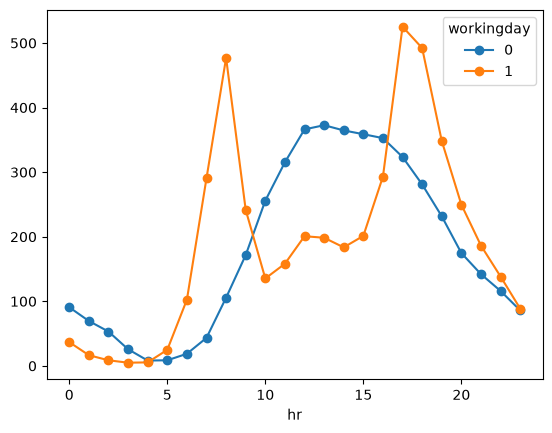

In [102]:
hourly_days = (
    df.groupby(["hr", "workingday"])["cnt"]
      .mean()
      .unstack()
)

hourly_days.plot(
    kind="line",
    marker="o"
)

### Average hourly bike-rental demand: working vs non-working days

- The working-day demand curve broadly resembles the overall hourly demand pattern. This is reasonable because working days account for approximately 68% of the dataset's observations.

- Working days show pronounced demand peaks around 8 AM and 5–6 PM, with lower average demand between these periods. This pattern is consistent with potential commuting-related demand.

- Non-working days follow a different pattern. Average demand rises during the morning and peaks around noon to early afternoon, rather than showing the same pronounced morning and evening peaks as working days.

- Non-working days also have higher average rental counts during the overnight and early-morning hours. Later in the afternoon and evening, demand declines in both groups.

- Overall, the differences between the two curves suggest that the time-of-day pattern in bike-rental demand varies depending on whether a day is classified as a working day. The commuting explanation is plausible, but the chart alone cannot establish the cause of these differences.

- Note: `workingday = 0` includes weekends and holidays, so these observations do not distinguish between the two groups.

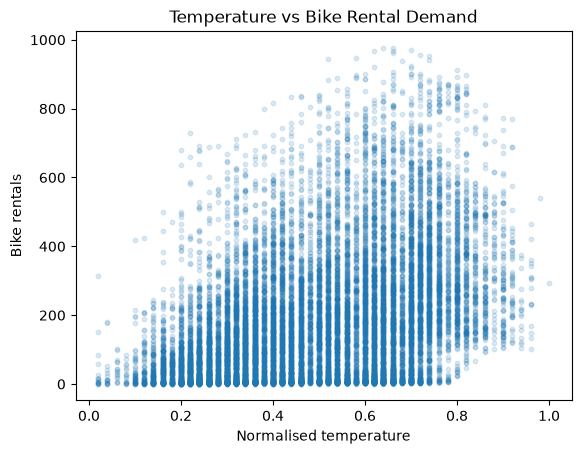

In [103]:
plt.scatter(
    df["temp"],
    df["cnt"],
    alpha=0.15,
    s=10
)
plt.xlabel("Normalised temperature")
plt.ylabel("Bike rentals")
plt.title("Temperature vs Bike Rental Demand")
plt.show()

The scatter plot suggests that higher rental counts occur more frequently at moderate to higher temperatures. However, there is substantial variability in rental counts at similar temperatures, indicating that temperature alone does not explain demand. The dense concentration of observations with low rental counts may partly reflect low-demand hours, such as overnight periods. Further analysis could investigate how temperature relates to demand after accounting for time of day and working-day status.

### It would be better to visualise the possible correlation between the demands and the temperatures if bins were used to group them into intervals and find the average demand/count for each interval. ###

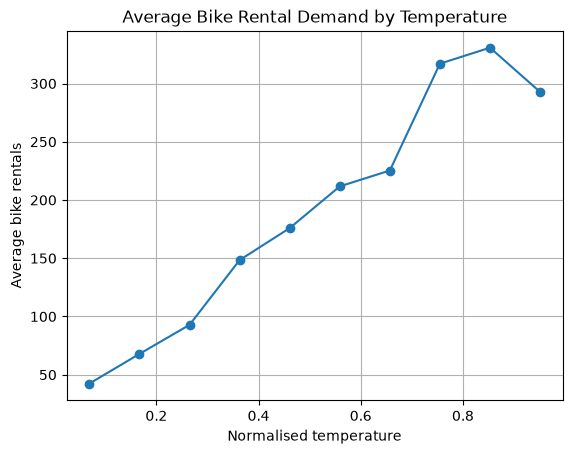

In [104]:
temp_bins = pd.cut(df["temp"], bins=10)

temp_demand = (
    df.groupby(temp_bins, observed=True)["cnt"]
      .mean()
)

temp_demand.index = [
    interval.mid for interval in temp_demand.index
]

temp_demand.plot(kind="line", marker="o")

plt.xlabel("Normalised temperature")
plt.ylabel("Average bike rentals")
plt.title("Average Bike Rental Demand by Temperature")
plt.grid(True)
plt.show()

### Temperature and bike-rental demand

The binned plot reveals a clear positive association between normalised temperature and average bike-rental demand across most of the observed temperature range. Average demand increases as temperature rises, reaching its highest level around the 0.85 temperature value before declining slightly in the highest temperature bin.

This suggests that temperature may be a useful feature for predicting bike-rental demand. However, the relationship is not perfectly linear, and temperature alone does not explain all the variation in rental counts. Other factors, such as the hour of the day, season and working-day status, may also contribute to the observed pattern. This plot shows an association rather than proving that higher temperatures cause greater rental demand.

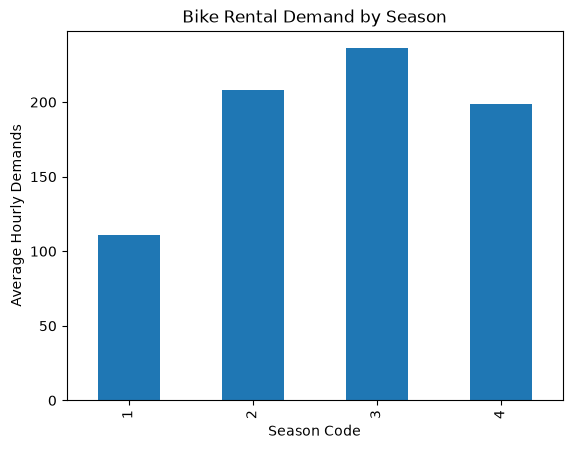

In [105]:
seasonal_demand = df.groupby("season")["cnt"].mean()

seasonal_demand.plot(kind="bar")

plt.xlabel("Season Code")
plt.ylabel("Average Hourly Demands")
plt.title("Bike Rental Demand by Season")
plt.show()

### Average hourly bike-rental demand by season

- The plot shows that summer (season 3) has the highest average hourly rental demand, at approximately 236 bikes, followed by spring (season 2) at approximately 208, autumn (season 4) at approximately 198, and winter (season 1) at approximately 111.
- Spring and autumn have relatively similar average demand, whereas summer shows a more noticeable increase. Winter has substantially lower average demand than the other seasons.
- These observations suggest that average hourly bike-rental demand varies across seasons. Season may therefore be a useful feature when predicting demand.
- However, this plot alone does not establish how much season contributes to predictive performance independently of other features, such as temperature, hour of the day and working-day status.

### Checking Correlations
• 0.0 to 0.1: None or very weak <br>
• 0.1 to 0.3: Low <br>
• 0.3 to 0.5: Moderate <br>
• 0.5 to 0.7: High <br>
• 0.7 to 1.0: Very high (or a perfect linear fit at ± 1) <br>

In [106]:
# sns.heatmap(df.loc[:, df.columns != 'dteday']) # w/out the "dteday" column 

** need to normalise the data first! **

In [107]:
matrix = df.iloc[:, df.columns != "dteday"].corr(method='pearson')
display(matrix)

,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,cnt
season,1.000000,-0.010742,0.830386,-0.006117,-0.009585,-0.002335,0.013743,-0.014524,0.312025,0.319380,0.150625,-0.149773,0.178056
yr,-0.010742,1.000000,-0.010473,-0.003867,0.006692,-0.004485,-0.002196,-0.019157,0.040913,0.039222,-0.083546,-0.008740,0.250495
mnth,0.830386,-0.010473,1.000000,-0.005772,0.018430,0.010400,-0.003477,0.005400,0.201691,0.208096,0.164411,-0.135386,0.120638
hr,-0.006117,-0.003867,-0.005772,1.000000,0.000479,-0.003498,0.002285,-0.020203,0.137603,0.133750,-0.276498,0.137252,0.394071
holiday,-0.009585,0.006692,0.018430,0.000479,1.000000,-0.102088,-0.252471,-0.017036,-0.027340,-0.030973,-0.010588,0.003988,-0.030927
weekday,-0.002335,-0.004485,0.010400,-0.003498,-0.102088,1.000000,0.035955,0.003311,-0.001795,-0.008821,-0.037158,0.011502,0.026900
workingday,0.013743,-0.002196,-0.003477,0.002285,-0.252471,0.035955,1.000000,0.044672,0.055390,0.054667,0.015688,-0.011830,0.030284
weathersit,-0.014524,-0.019157,0.005400,-0.020203,-0.017036,0.003311,0.044672,1.000000,-0.102640,-0.105563,0.418130,0.026226,-0.142426
temp,0.312025,0.040913,0.201691,0.137603,-0.027340,-0.001795,0.055390,-0.102640,1.000000,0.987672,-0.069881,-0.023125,0.404772
atemp,0.319380,0.039222,0.208096,0.133750,-0.030973,-0.008821,0.054667,-0.105563,0.987672,1.000000,-0.051918,-0.062336,0.400929


cnt         0.178056  0.250495  0.120638  **0.394071** -0.030927  0.026900  0.030284  -0.142426  **0.404772**  **0.400929** -0.322911  0.093234 

The highlighted values are the noticeably largest perason correlations amongst the columns in comparison to the "cnt" column. <br>
- The first is the <i>hr</i> column, which as already seen, the records are per hour and also it is one of the most important features (the other are a bit more complimentary)
- The second value is the <i>temp</i> column, which is actually the strongest correlated column to the cnt one! This shows that even though for the extreme variability of the temperature column, it is another imporant feature to take into consideration later when training a model.
- The third value is <i>atemp</i>>, the which is also more correlated than the hour one but less of the temperature. It is extremely similar to the temp column when it comes to variability, and it's another column to conisder later.

<Axes: >

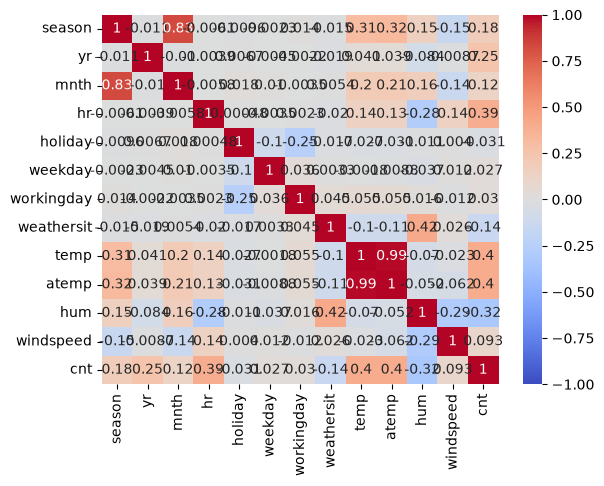

In [108]:
sns.heatmap(
    matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

The correlation between temp and atemp is 0.99, extremely high! <br>
This introduces a new ML concept, **multicollinearity**! <br>
This means that when two features are highly correlated with each other, they can contain largely overlapping information. <br>
For example, in a linear regression model, having both features can make it harder to interpret their individual coefficients because the model has difficulty distinguishing their separate contributions. <br>


### Pearson Correlation Analysis

Pearson correlation was used to investigate linear associations between the numerical features and the target variable (`cnt`).

The strongest positive correlations with rental demand are:

- `temp`: 0.405
- `atemp`: 0.401
- `hr`: 0.394

These results suggest that temperature, apparent temperature and hour of the day have relatively stronger positive linear associations with rental demand compared with the other features.

Humidity (`hum`) has a negative correlation of approximately -0.323, suggesting that higher humidity tends to be associated with lower rental counts.

Two particularly high correlations between input features are also worth noting:

- `temp` and `atemp`: 0.988
- `season` and `mnth`: 0.830

These pairs contain potentially overlapping information, which may be worth investigating when selecting or comparing features for the regression model.

However, Pearson correlation only measures pairwise linear association. It does not establish causality or determine the overall predictive importance of a feature, particularly when nonlinear relationships and interactions may exist.

**train and compare:**
- A model using temp.
- A model using atemp.
- A model using both.

### Baseline and Model Creation

In [109]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   dteday      17379 non-null  str    
 1   season      17379 non-null  int64  
 2   yr          17379 non-null  int64  
 3   mnth        17379 non-null  int64  
 4   hr          17379 non-null  int64  
 5   holiday     17379 non-null  int64  
 6   weekday     17379 non-null  int64  
 7   workingday  17379 non-null  int64  
 8   weathersit  17379 non-null  int64  
 9   temp        17379 non-null  float64
 10  atemp       17379 non-null  float64
 11  hum         17379 non-null  float64
 12  windspeed   17379 non-null  float64
 13  cnt         17379 non-null  int64  
dtypes: float64(4), int64(9), str(1)
memory usage: 1.9 MB


In [110]:
df["dteday"] = pd.to_datetime(df["dteday"])

df = df.sort_values(["dteday", "hr"]) # sort based on chronological order, eve though they might already be

split_index = int(len(df) * 0.8) # get the 80 percent ith index

train = df.iloc[:split_index] # 80% train data
test = df.iloc[split_index:] # 20% test

In [111]:
train_features = train.drop(columns="cnt")
# train_targets = train[["cnt"]] # no need to be a dataframe since only one collumn `cnt` is being predicted
train_targets = train["cnt"]
train_features.head()


,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed
0,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0
1,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0
2,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0
3,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0
4,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0


In [112]:
train_targets.head()

0    16
1    40
2    32
3    13
4     1
Name: cnt, dtype: int64

In [113]:
test_features = test.drop(columns="cnt")
# test_targets = test[["cnt"]] # no need to be a dataframe since only one collumn `cnt` is being predicted
test_targets = test["cnt"]

In [114]:
# use the `median` baseline strategy
baseline_predicitons = len(test_targets) * [train_targets.median()]

In [115]:
display(baseline_predicitons)

[np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),
 np.float64(130.0),


## Now for the model creation

In [117]:
# multiple linear regresion 
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

train_features = train_features.drop(columns=["dteday"])
test_features = test_features.drop(columns=["dteday"])

model = LinearRegression()
model.fit(train_features, train_targets)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](12,)","[ 8.25, 76.8 , 2.51,..., 214.45,-168.79, 33.34]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](12,)","['season','yr','mnth',...,'atemp','hum','windspeed']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-10.97
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,12
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(12)


In [119]:
model_predictions = model.predict(test_features)
print("Mean Absolute Error (MAE):", mean_absolute_error(test_targets, model_predictions))
print("R-squared Score:", r2_score(test_targets, model_predictions))

Mean Absolute Error (MAE): 138.29175310827355
R-squared Score: 0.30902462052952906


In [121]:
print("Mean Absolute Error (MAE):", mean_absolute_error(test_targets, baseline_predicitons))
print("R-squared Score:", r2_score(test_targets, baseline_predicitons))

Mean Absolute Error (MAE): 182.8777330264672
R-squared Score: -0.29009719320598215


### Initial Multiple Linear Regression Evaluation

- The multiple linear regression model achieves an MAE of approximately 138.29, compared with 182.88 for the median baseline.
- This represents an improvement of approximately 24.4% in average absolute prediction error.
- The model's R² score is 0.309, suggesting that it explains approximately 30.9% of the variation in the test targets relative to the mean-prediction reference.
- The baseline produces a negative R² score (-0.290), indicating worse squared-error performance than the test-set mean reference.
- Overall, the multiple linear regression model outperforms the baseline, but its relatively modest R² suggests that it does not capture all the patterns influencing hourly bike-rental demand.

This provides an initial benchmark for comparing more sophisticated regression models.

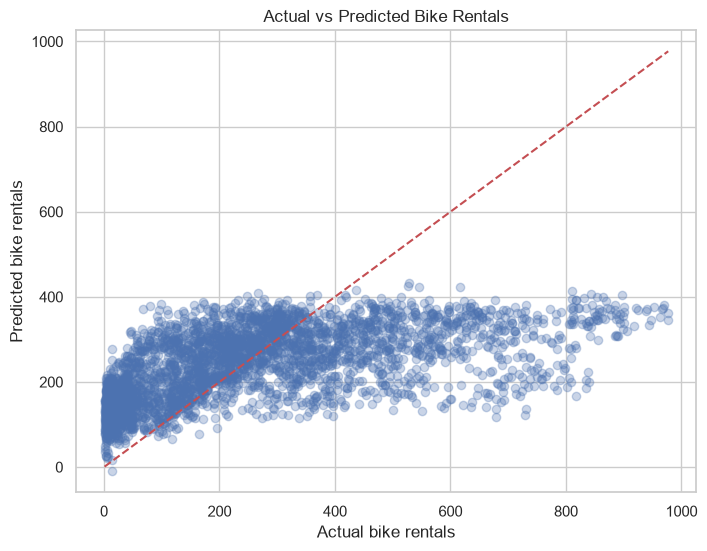

In [122]:
plt.figure(figsize=(8, 6))

plt.scatter(test_targets, model_predictions, alpha=0.3)

plt.xlabel("Actual bike rentals")
plt.ylabel("Predicted bike rentals")
plt.title("Actual vs Predicted Bike Rentals")

# Perfect prediction reference
plt.plot(
    [test_targets.min(), test_targets.max()],
    [test_targets.min(), test_targets.max()],
    "r--"
)

plt.show()

### Actual vs predicted:

The predictions are concentrated within a relatively narrow range compared with the actual rental counts. The model tends to underestimate particularly high-demand observations, suggesting that it struggles to capture peak rental demand.

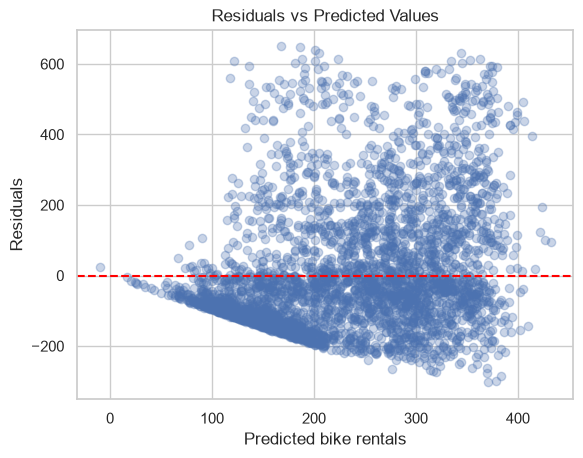

In [123]:
residuals = test_targets - model_predictions

plt.scatter(model_predictions, residuals, alpha=0.3)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted bike rentals")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Values")

plt.show()

### Residual analysis:

The residuals show considerable variation and are not randomly distributed around zero. Both overestimation and underestimation occur, with some particularly large errors. This suggests that the model does not capture all the patterns influencing rental demand.

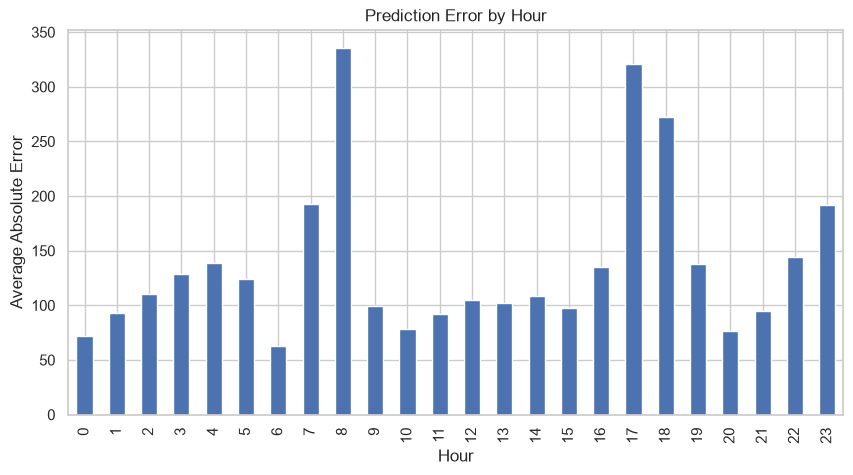

In [138]:
error_df = pd.DataFrame({
    "hr": test_features["hr"],
    "absolute_error": np.abs(test_targets - model_predictions),
    "workingday": test_features["workingday"],
    "residual": test_targets - model_predictions
})

error_by_hour = error_df.groupby("hr")["absolute_error"].mean()

error_by_hour.plot(kind="bar", figsize=(10, 5))

plt.xlabel("Hour")
plt.ylabel("Average Absolute Error")
plt.title("Prediction Error by Hour")
plt.show()

### Prediction error by hour:

The highest average absolute prediction errors occur around 8 AM and 5–6 PM, which coincide with the major demand peaks identified during EDA. This suggests that the model struggles to predict demand accurately during these periods, potentially due to differences between working and non-working days and other influencing factors.

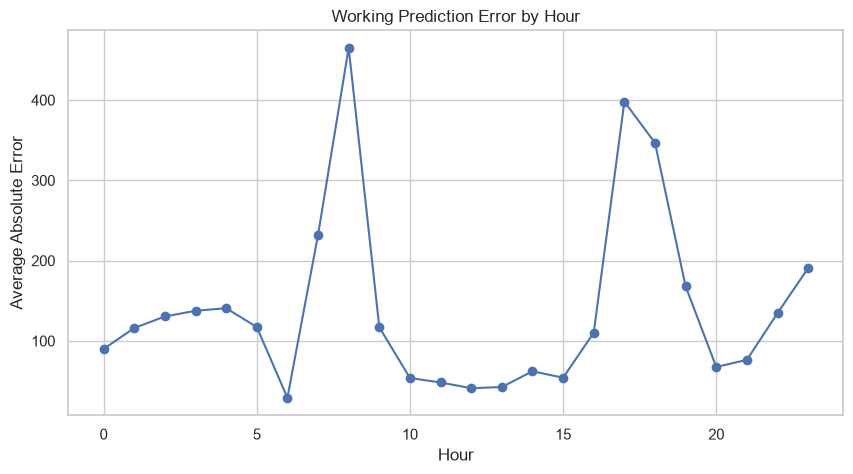

In [135]:
working_error_by_hour = (
    error_df[error_df["workingday"] == 1]
    .groupby("hr")["absolute_error"]
    .mean()
)

working_error_by_hour.plot(kind="line", marker="o", figsize=(10, 5))

plt.xlabel("Hour")
plt.ylabel("Average Absolute Error")
plt.title("Working Prediction Error by Hour")
plt.show()

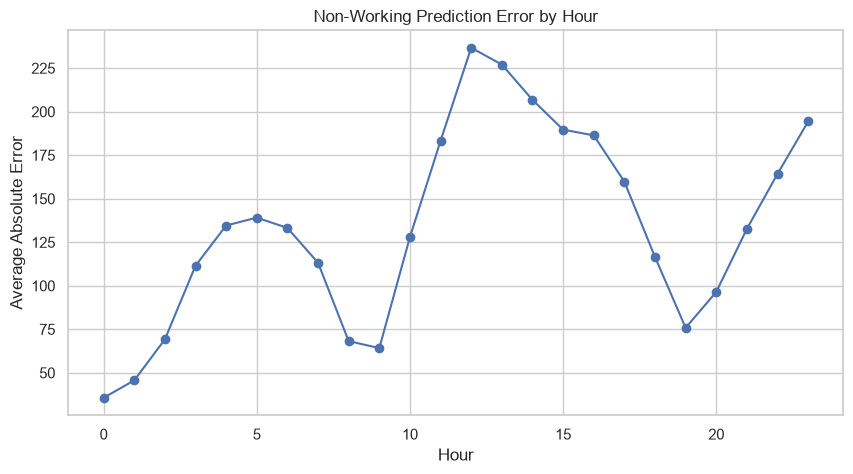

In [136]:
non_working_error_by_hour = (
    error_df[error_df["workingday"] == 0]
    .groupby("hr")["absolute_error"]
    .mean()
)

non_working_error_by_hour.plot(kind="line", marker="o", figsize=(10, 5))

plt.xlabel("Hour")
plt.ylabel("Average Absolute Error")
plt.title("Non-Working Prediction Error by Hour")
plt.show()

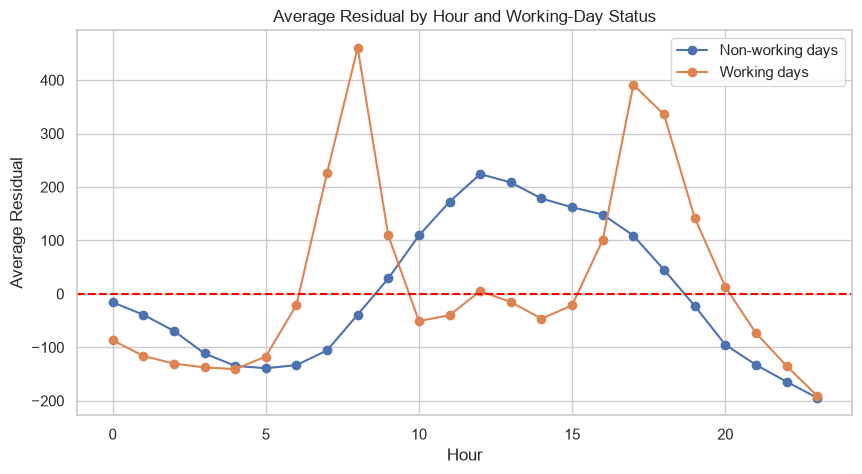

In [142]:
residual_error_by_hour = (
    error_df.groupby(["hr", "workingday"])["residual"]
    .mean()
    .unstack("workingday")
)

residual_error_by_hour = residual_error_by_hour.rename(
    columns={
        0: "Non-working days",
        1: "Working days"
    }
)

residual_error_by_hour.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Hour")
plt.ylabel("Average Residual")
plt.title("Average Residual by Hour and Working-Day Status")
plt.legend()
plt.show()


### Linear Regression Model – Error Analysis

- It captures some general relationships between the features and rental demand, as demonstrated by its improvement over the baseline.
- It struggles to capture the magnitude of demand during high-demand periods.
- It tends to underestimate commuting-hour demand on working days and midday demand on non-working days.
- It tends to overestimate demand during quieter early-morning and late-evening periods.
- Its prediction errors vary depending on the hour and working-day status.